In [1]:
# Accuracy Comparison: Original Data vs Engineered Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, accuracy_score

# Load Dataset
df_train = pd.read_csv('dataset/cleaned_train.csv')
df_test = pd.read_csv('dataset/test.csv')
df = pd.concat([df_train, df_test], axis=0, ignore_index=True)

# Common Preprocessing (Fill Missing & Encode Target)
# Fill missing
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

# Encode Target
target_col = 'Placement_Status'
df[target_col] = df[target_col].map({"Placed": 1, "Not Placed": 0})
if df[target_col].isnull().any():
    df[target_col] = LabelEncoder().fit_transform(df[target_col].astype(str))

# Encode Categoricals
cat_cols = [c for c in cat_cols if c != target_col and c != 'Student_ID']
for c in cat_cols:
    df[c] = LabelEncoder().fit_transform(df[c])

df = df.drop(columns=['Student_ID'], errors='ignore')
print("Base data loaded and encoded successfully.")

Base data loaded and encoded successfully.


C:\Users\Pansh\AppData\Local\Temp\ipykernel_13104\3510561035.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


In [2]:
# Experiment 1: Original Model Accuracy (No Feature Engineering)

# Use only original features
X_base = df.drop(columns=[target_col])
y_base = df[target_col]

# Scale
scaler_base = StandardScaler()
X_base_scaled = scaler_base.fit_transform(X_base)

# Train/Test Split
X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(X_base_scaled, y_base, test_size=0.2, random_state=42)

# Train Model
rf_base = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_base.fit(X_train_base, y_train_base)

# Evaluate
y_pred_base = rf_base.predict(X_test_base)
y_proba_base = rf_base.predict_proba(X_test_base)[:, 1]

acc_base = accuracy_score(y_test_base, y_pred_base)
roc_base = roc_auc_score(y_test_base, y_proba_base)

print(f"Original Dataset - Accuracy: {acc_base*100:.2f}% | ROC-AUC: {roc_base:.4f}")

Original Dataset - Accuracy: 100.00% | ROC-AUC: 1.0000


In [3]:
# Experiment 2: Your Model Accuracy (With Feature Engineering)
df_eng = df.copy()

# Add your custom engineered features
# Normalization helper
def norm(series):
    return (series - series.min()) / (series.max() - series.min() + 1e-9)

df_eng['AcademicScore'] = 0.60 * norm(df_eng['CGPA']) - 0.40 * norm(df_eng['Backlogs'])
df_eng['TechnicalScore'] = 0.50 * norm(df_eng['Coding_Skills']) + 0.30 * norm(df_eng['Projects']) + 0.20 * norm(df_eng['Aptitude_Test_Score'])
df_eng['ExperienceScore'] = 0.50 * norm(df_eng['Internships']) + 0.30 * norm(df_eng['Certifications']) + 0.20 * norm(df_eng['Age'])
df_eng['CommunicationScore'] = 0.60 * norm(df_eng['Communication_Skills']) + 0.40 * norm(df_eng['Soft_Skills_Rating'])
df_eng['ProjectScore'] = norm(df_eng['Projects'])
df_eng['CodingIndex'] = 0.60 * norm(df_eng['Coding_Skills']) + 0.40 * norm(df_eng['Aptitude_Test_Score'])

df_eng['OverallSkillScore'] = (
    0.30 * df_eng['TechnicalScore'] +
    0.20 * df_eng['AcademicScore'] +
    0.20 * df_eng['CommunicationScore'] +
    0.15 * df_eng['ExperienceScore'] +
    0.15 * df_eng['ProjectScore']
)

# Prepare Data
X_eng = df_eng.drop(columns=[target_col])
y_eng = df_eng[target_col]

# Scale
scaler_eng = StandardScaler()
X_eng_scaled = scaler_eng.fit_transform(X_eng)

# Train/Test Split
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(X_eng_scaled, y_eng, test_size=0.2, random_state=42)

# Train Model
rf_eng = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_eng.fit(X_train_eng, y_train_eng)

# Evaluate
y_pred_eng = rf_eng.predict(X_test_eng)
y_proba_eng = rf_eng.predict_proba(X_test_eng)[:, 1]

acc_eng = accuracy_score(y_test_eng, y_pred_eng)
roc_eng = roc_auc_score(y_test_eng, y_proba_eng)

print(f"Engineered Dataset (Your Model) - Accuracy: {acc_eng*100:.2f}% | ROC-AUC: {roc_eng:.4f}")

Engineered Dataset (Your Model) - Accuracy: 100.00% | ROC-AUC: 1.0000


C:\Users\Pansh\AppData\Local\Temp\ipykernel_13104\1681374667.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=results, ax=ax[0], palette=['#e74c3c', '#2ecc71'])
C:\Users\Pansh\AppData\Local\Temp\ipykernel_13104\1681374667.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='ROC-AUC', data=results, ax=ax[1], palette=['#e74c3c', '#2ecc71'])


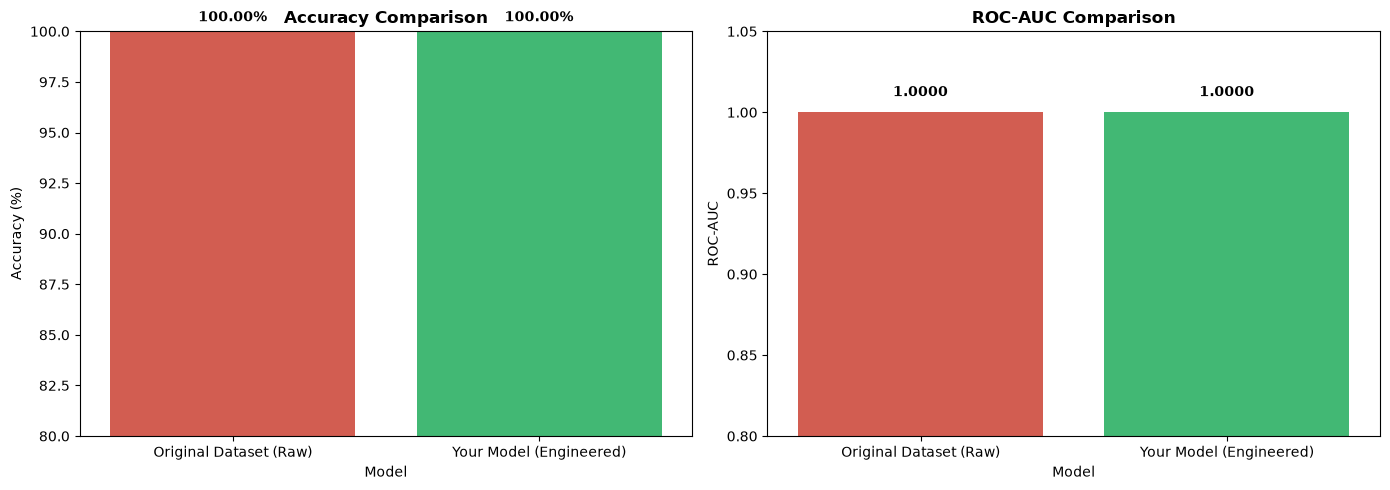

In [4]:
# Experiment 3: Visual Comparison
results = pd.DataFrame({
    'Model': ['Original Dataset (Raw)', 'Your Model (Engineered)'],
    'Accuracy': [acc_base * 100, acc_eng * 100],
    'ROC-AUC': [roc_base, roc_eng]
})

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
sns.barplot(x='Model', y='Accuracy', data=results, ax=ax[0], palette=['#e74c3c', '#2ecc71'])
ax[0].set_ylim(80, 100)
ax[0].set_title('Accuracy Comparison', fontweight='bold')
ax[0].set_ylabel('Accuracy (%)')
for i, v in enumerate(results['Accuracy']):
    ax[0].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

# ROC-AUC Plot
sns.barplot(x='Model', y='ROC-AUC', data=results, ax=ax[1], palette=['#e74c3c', '#2ecc71'])
ax[1].set_ylim(0.8, 1.05)
ax[1].set_title('ROC-AUC Comparison', fontweight='bold')
for i, v in enumerate(results['ROC-AUC']):
    ax[1].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()